# xPatch: Dual-Stream Time Series Forecasting with Exponential Seasonal-Trend Decomposition

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/xpatch_dual_stream.ipynb)

**Paper**: Artyom Stitsyuk, Jaesik Choi. *xPatch: Dual-Stream Time Series Forecasting with Exponential Seasonal-Trend Decomposition.* **AAAI 2025**. [arXiv:2412.17323](https://arxiv.org/abs/2412.17323)

**Official code**: [github.com/stitsyuk/xPatch](https://github.com/stitsyuk/xPatch)

**Key ideas** (re-implemented from scratch in PyTorch, faithful to the official code):
- **EMA decomposition**: the trend is an exponential moving average (α = 0.3) instead of a fixed-window moving average; seasonal = input − trend.
- **Dual stream**:
  - *non-linear stream* for the **seasonal** part: patching (16/8) → patch embedding → depthwise + pointwise CNN with a residual path → MLP flatten head;
  - *linear stream* for the **trend** part: a purely linear MLP (FC → AvgPool → LayerNorm, twice → FC), no activations.
- The two forecasts are concatenated and fused by a linear layer. Channel-independent, with RevIN.
- **Training tricks**: an **arctangent loss** that down-weights far-horizon errors, and a **sigmoid learning-rate schedule** (warm-up then slow decay).

**Benchmark here**: ETTh1, multivariate (7 channels), lookback **L = 96**, horizon **H = 96** — the paper's *unified* setting, with the official `scripts/xPatch_unified.sh` hyper-parameters. (The paper also reports a *hyper-parameter search* setting with longer lookbacks, from `scripts/xPatch_search.sh`; it is not used here.)

In [1]:
# Everything this notebook needs (torch, numpy, pandas, matplotlib, scikit-learn) is preinstalled on Colab.
import math, time, json, random, copy
import numpy as np, pandas as pd, torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 2024
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.12.1+cu130


## Data: ETTh1 with the standard splits

Standard Informer/Autoformer/TSLib borders (12/4/4 months), `StandardScaler` fitted on the training rows only, metrics on the scaled data.

In [2]:
import numpy as np, pandas as pd, torch
from sklearn.preprocessing import StandardScaler
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

In [3]:
class Config:
    # official scripts/xPatch_unified.sh (ETTh1) + run.py defaults
    seq_len = 96
    pred_len = 96
    enc_in = 7
    patch_len = 16
    stride = 8
    padding_patch = "end"
    revin = 1
    ma_type = "ema"
    alpha = 0.3
    learning_rate = 0.0005
    batch_size = 2048
    train_epochs = 100
    patience = 10

cfg = Config()
L, H = cfg.seq_len, cfg.pred_len

train_arr, val_arr, test_arr, cols = load_etth1(L)
train_ds, val_ds, test_ds = WindowDataset(train_arr, L, H), WindowDataset(val_arr, L, H), WindowDataset(test_arr, L, H)
g = torch.Generator().manual_seed(SEED)
# official loader: shuffle + drop_last for training (8449 windows -> 4 batches of 2048 per epoch)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, drop_last=True, generator=g)
val_loader = torch.utils.data.DataLoader(val_ds, batch_size=1024, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=1024, shuffle=False)
print("channels:", cols)
print(f"windows  train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}  | train steps/epoch={len(train_loader)}")

channels: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
windows  train=8449  val=2785  test=2785  | train steps/epoch=4


## RevIN

Per-instance, per-channel normalisation with learnable affine parameters; the forecast is de-normalised with the same statistics:
$$\tilde x = \gamma\,\frac{x-\mu}{\sigma}+\beta, \qquad \hat y = \frac{\tilde y-\beta}{\gamma}\,\sigma+\mu .$$

In [4]:
class RevIN(nn.Module):
    def __init__(self, num_features, eps=1e-5, affine=True):
        super().__init__()
        self.eps, self.affine = eps, affine
        if affine:
            self.affine_weight = nn.Parameter(torch.ones(num_features))
            self.affine_bias = nn.Parameter(torch.zeros(num_features))

    def forward(self, x, mode):
        if mode == "norm":
            self.mean = x.mean(1, keepdim=True).detach()
            self.stdev = torch.sqrt(x.var(1, keepdim=True, unbiased=False) + self.eps).detach()
            x = (x - self.mean) / self.stdev
            if self.affine:
                x = x * self.affine_weight + self.affine_bias
            return x
        if self.affine:
            x = (x - self.affine_bias) / (self.affine_weight + self.eps * self.eps)
        return x * self.stdev + self.mean

## EMA seasonal-trend decomposition

The trend is the exponential moving average
$$s_0 = x_0, \qquad s_t = \alpha x_t + (1-\alpha)\, s_{t-1},$$
and the seasonal part is $x - s$. Unrolled, $s_t = (1-\alpha)^t x_0 + \sum_{j=1}^{t}\alpha(1-\alpha)^{t-j}x_j$, which the official code evaluates **in parallel** with a cumulative sum:
$$s_t = \frac{\sum_{j\le t} w_j x_j}{(1-\alpha)^{T-1-t}}, \quad w_j = (1-\alpha)^{T-1-j}\cdot\begin{cases}1 & j=0\\ \alpha & j>0\end{cases}$$
(computed in float64 for stability). Compared with a moving-average kernel, EMA puts more weight on recent observations and needs no padding.

In [5]:
class EMA(nn.Module):
    def __init__(self, alpha):
        super().__init__()
        self.alpha = alpha

    def forward(self, x):                        # x: (B, T, C)
        _, t, _ = x.shape
        powers = torch.flip(torch.arange(t, dtype=torch.double), dims=(0,))
        weights = torch.pow(1 - self.alpha, powers).to(x.device)
        divisor = weights.clone()
        weights[1:] = weights[1:] * self.alpha
        x = torch.cumsum(x * weights.reshape(1, t, 1), dim=1) / divisor.reshape(1, t, 1)
        return x.to(torch.float32)


class DECOMP(nn.Module):
    def __init__(self, alpha):
        super().__init__()
        self.ma = EMA(alpha)

    def forward(self, x):
        trend = self.ma(x)
        return x - trend, trend                  # seasonal, trend

# sanity check against the naive recursion
_x = torch.randn(2, 96, 3)
_s = [_x[:, 0]]
for _t in range(1, 96):
    _s.append(0.3 * _x[:, _t] + 0.7 * _s[-1])
print("EMA parallel vs recursive max diff:", (EMA(0.3)(_x) - torch.stack(_s, 1)).abs().max().item())

EMA parallel vs recursive max diff: 1.1920928955078125e-07


## Dual-stream network

**Non-linear (seasonal) stream** — per channel:
1. *Patching*: replicate-pad the end by `stride`, then unfold into $N = (96-16)/8 + 2 = 12$ patches of length $P=16$.
2. *Patch embedding*: `Linear(P → P²)` + GELU + BatchNorm (over patches).
3. *Depthwise conv*: `Conv1d(N, N, kernel=P, stride=P, groups=N)` shrinks each $P^2$ embedding back to $P$, + GELU + BN; a **residual** `Linear(P² → P)` is added.
4. *Pointwise conv*: `Conv1d(N, N, 1)` mixes information across patches, + GELU + BN.
5. *Flatten head*: `Linear(N·P → 2H)` + GELU + `Linear(2H → H)`.

**Linear (trend) stream** — per channel, no activation functions:
$$t \xrightarrow{\text{FC}} 4H \xrightarrow{\text{AvgPool}_2} 2H \xrightarrow{\text{LN}} \xrightarrow{\text{FC}} H \xrightarrow{\text{AvgPool}_2} H/2 \xrightarrow{\text{LN}} \xrightarrow{\text{FC}} H.$$

**Fusion**: `Linear(2H → H)` on the concatenation of both stream outputs.

In [6]:
class Network(nn.Module):
    def __init__(self, seq_len, pred_len, patch_len, stride, padding_patch):
        super().__init__()
        self.pred_len, self.patch_len, self.stride, self.padding_patch = pred_len, patch_len, stride, padding_patch
        self.dim = patch_len * patch_len
        self.patch_num = (seq_len - patch_len) // stride + 1
        if padding_patch == "end":
            self.padding_patch_layer = nn.ReplicationPad1d((0, stride))
            self.patch_num += 1
        N, P = self.patch_num, patch_len

        # ---- non-linear (seasonal) stream ----
        self.fc1 = nn.Linear(P, self.dim);  self.gelu1 = nn.GELU(); self.bn1 = nn.BatchNorm1d(N)      # patch embedding
        self.conv1 = nn.Conv1d(N, N, P, P, groups=N); self.gelu2 = nn.GELU(); self.bn2 = nn.BatchNorm1d(N)  # depthwise
        self.fc2 = nn.Linear(self.dim, P)                                                              # residual
        self.conv2 = nn.Conv1d(N, N, 1, 1); self.gelu3 = nn.GELU(); self.bn3 = nn.BatchNorm1d(N)       # pointwise
        self.flatten1 = nn.Flatten(start_dim=-2)
        self.fc3 = nn.Linear(N * P, pred_len * 2); self.gelu4 = nn.GELU(); self.fc4 = nn.Linear(pred_len * 2, pred_len)

        # ---- linear (trend) stream ----
        self.fc5 = nn.Linear(seq_len, pred_len * 4); self.avgpool1 = nn.AvgPool1d(2); self.ln1 = nn.LayerNorm(pred_len * 2)
        self.fc6 = nn.Linear(pred_len * 2, pred_len); self.avgpool2 = nn.AvgPool1d(2); self.ln2 = nn.LayerNorm(pred_len // 2)
        self.fc7 = nn.Linear(pred_len // 2, pred_len)

        # ---- stream fusion ----
        self.fc8 = nn.Linear(pred_len * 2, pred_len)

    def forward(self, s, t):                     # s, t: (B, T, C)
        B, T, C = s.shape
        s = s.permute(0, 2, 1).reshape(B * C, T)  # channel independence
        t = t.permute(0, 2, 1).reshape(B * C, T)

        # seasonal stream
        if self.padding_patch == "end":
            s = self.padding_patch_layer(s)
        s = s.unfold(dimension=-1, size=self.patch_len, step=self.stride)   # (B*C, N, P)
        s = self.bn1(self.gelu1(self.fc1(s)))
        res = s
        s = self.bn2(self.gelu2(self.conv1(s)))
        s = s + self.fc2(res)
        s = self.bn3(self.gelu3(self.conv2(s)))
        s = self.fc4(self.gelu4(self.fc3(self.flatten1(s))))

        # trend stream
        t = self.ln1(self.avgpool1(self.fc5(t)))
        t = self.ln2(self.avgpool2(self.fc6(t)))
        t = self.fc7(t)

        x = self.fc8(torch.cat((s, t), dim=1))
        return x.reshape(B, C, self.pred_len).permute(0, 2, 1)


class xPatch(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.revin = cfg.revin
        self.revin_layer = RevIN(cfg.enc_in, affine=True)
        self.decomp = DECOMP(cfg.alpha)
        self.net = Network(cfg.seq_len, cfg.pred_len, cfg.patch_len, cfg.stride, cfg.padding_patch)

    def forward(self, x):
        if self.revin:
            x = self.revin_layer(x, "norm")
        seasonal, trend = self.decomp(x)
        x = self.net(seasonal, trend)
        if self.revin:
            x = self.revin_layer(x, "denorm")
        return x


model = xPatch(cfg).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"xPatch parameters: {n_params:,}  (patches per channel: {model.net.patch_num})")
with torch.no_grad():
    print("output shape:", model(torch.randn(2, L, cfg.enc_in, device=device)).shape)

xPatch parameters: 143,982  (patches per channel: 12)


output shape: torch.Size([2, 96, 7])


## Arctangent loss and sigmoid learning-rate schedule

**Arctangent loss.** Errors at horizon step $i = 1..H$ are scaled by
$$\rho(i) = -\arctan(i) + \frac{\pi}{4} + 1 ,$$
so $\rho(1)=1$ and $\rho$ decays slowly to $\approx 0.21$ — near-term errors matter more, but far steps are never ignored. The official code multiplies predictions and targets by $\rho$ and applies **L1** loss (the same weighted MAE is used for validation / early stopping).

**Sigmoid schedule.** After epoch $e$ the learning rate is set to
$$\eta_e = \eta\left[\frac{1}{1+e^{-k(e-w)}} - \frac{1}{1+e^{-\frac{k}{s}(e-ws)}}\right], \qquad k=0.5,\ s=10,\ w=10,$$
a logistic warm-up over the first ~20 epochs followed by a slow logistic decay. (As in the official code, epoch 1 uses the base rate $\eta$, the schedule applies from epoch 2 on.)

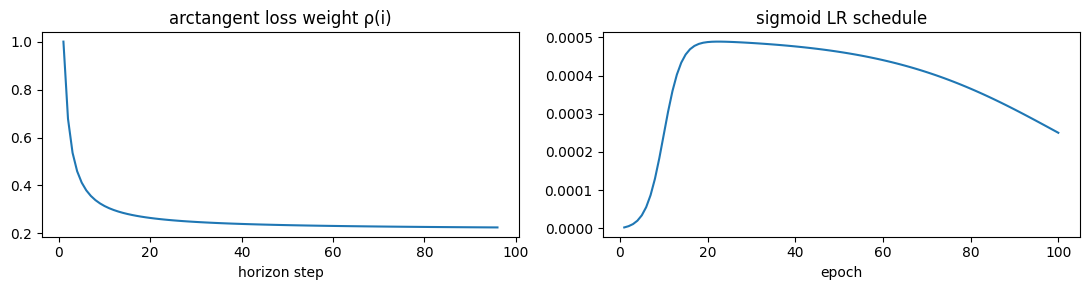

In [7]:
ratio = torch.tensor([-math.atan(i + 1) + math.pi / 4 + 1 for i in range(H)], dtype=torch.float64).unsqueeze(-1).to(device)

def arctan_l1(pred, true):
    return nn.functional.l1_loss(pred * ratio, true * ratio)

def sigmoid_lr(epoch, base_lr, k=0.5, s=10, w=10):
    return base_lr / (1 + np.exp(-k * (epoch - w))) - base_lr / (1 + np.exp(-k / s * (epoch - w * s)))

ep = np.arange(1, cfg.train_epochs + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(np.arange(1, H + 1), ratio.squeeze().cpu()); ax[0].set_title("arctangent loss weight ρ(i)"); ax[0].set_xlabel("horizon step")
ax[1].plot(ep, [sigmoid_lr(e, cfg.learning_rate) for e in ep]); ax[1].set_title("sigmoid LR schedule"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Training

As the official `exp_main.py`: AdamW (lr 5e-4, default weight decay), batch 2048, up to 100 epochs, arctangent-weighted L1 loss, sigmoid LR, early stopping with patience 10 on the arctangent-weighted validation MAE. With batch 2048 an epoch is only 4 optimiser steps, so 100 epochs take well under a minute on a T4.

In [8]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    P, Y = [], []
    for x, y in loader:
        P.append(model(x.to(device)).cpu()); Y.append(y)
    return torch.cat(P), torch.cat(Y)

seed_everything()
model = xPatch(cfg).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.learning_rate)

best_val, best_state, bad = float("inf"), None, 0
t0 = time.time()
for epoch in range(1, cfg.train_epochs + 1):
    model.train(); losses = []
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = arctan_l1(model(x), y)
        loss.backward(); optimizer.step()
        losses.append(loss.item())
    p, t = predict(model, val_loader)
    val_loss = arctan_l1(p.to(device), t.to(device)).item()
    flag = ""
    if val_loss < best_val:
        best_val, best_state, bad, flag = val_loss, copy.deepcopy(model.state_dict()), 0, "  *"
    else:
        bad += 1
    if epoch == 1 or epoch % 5 == 0 or bad >= cfg.patience:
        print(f"epoch {epoch:3d} | train loss {np.mean(losses):.4f} | val loss {val_loss:.4f} | val MSE {((p - t) ** 2).mean():.4f} "
              f"| lr {optimizer.param_groups[0]['lr']:.2e}{flag}")
    if bad >= cfg.patience:
        print(f"early stopping at epoch {epoch}"); break
    for pg in optimizer.param_groups:          # adjust_learning_rate(optimizer, epoch + 1, args) in the official loop
        pg["lr"] = sigmoid_lr(epoch, cfg.learning_rate)
train_seconds = time.time() - t0
model.load_state_dict(best_state)
print(f"training time: {train_seconds:.1f}s, best val loss {best_val:.4f}")

epoch   1 | train loss 0.1374 | val loss 0.1865 | val MSE 1.0592 | lr 5.00e-04  *


epoch   5 | train loss 0.1313 | val loss 0.1850 | val MSE 1.0464 | lr 1.96e-05  *


epoch  10 | train loss 0.1257 | val loss 0.1716 | val MSE 0.9372 | lr 1.84e-04  *


epoch  15 | train loss 0.1124 | val loss 0.1477 | val MSE 0.7626 | lr 4.34e-04  *


epoch  20 | train loss 0.1067 | val loss 0.1412 | val MSE 0.7179 | lr 4.86e-04  *


...

epoch  60 | train loss 0.1004 | val loss 0.1363 | val MSE 0.6819 | lr 4.43e-04


epoch  65 | train loss 0.1001 | val loss 0.1359 | val MSE 0.6788 | lr 4.29e-04  *


epoch  70 | train loss 0.0998 | val loss 0.1361 | val MSE 0.6793 | lr 4.12e-04


epoch  75 | train loss 0.0994 | val loss 0.1359 | val MSE 0.6777 | lr 3.93e-04


epoch  78 | train loss 0.0995 | val loss 0.1358 | val MSE 0.6773 | lr 3.80e-04
early stopping at epoch 78
training time: 8.3s, best val loss 0.1357


## Test evaluation

All 2785 stride-1 test windows (MSE / MAE averaged over windows, horizon steps and channels, on the standardised data).
With batch 2048 and `drop_last=True` the official test loader only scores the **first 2048** windows, so that number is reported as well for a like-for-like comparison with the paper.

In [9]:
PAPER_MSE, PAPER_MAE = 0.376, 0.386   # xPatch paper, Table 13 (unified setting, L=96), ETTh1 H=96

pred, true = predict(model, test_loader)
pred, true = pred.numpy(), true.numpy()
mse = float(((pred - true) ** 2).mean()); mae = float(np.abs(pred - true).mean())
n_dl = (len(test_ds) // cfg.batch_size) * cfg.batch_size
mse_dl = float(((pred[:n_dl] - true[:n_dl]) ** 2).mean()); mae_dl = float(np.abs(pred[:n_dl] - true[:n_dl]).mean())

print(f"xPatch  ETTh1  L={L} H={H}  ({len(test_ds)} test windows)")
print(f"  ours (all windows)             MSE {mse:.4f}  MAE {mae:.4f}")
print(f"  ours (drop_last, {n_dl} wins)   MSE {mse_dl:.4f}  MAE {mae_dl:.4f}")
print(f"  paper (unified L=96, AAAI 2025) MSE {PAPER_MSE:.3f}  MAE {PAPER_MAE:.3f}")
print("  TSLib refs: DLinear 0.386/0.400 | PatchTST 0.414/0.419 | iTransformer 0.386/0.405 | TimesNet 0.384/0.402")

xPatch  ETTh1  L=96 H=96  (2785 test windows)
  ours (all windows)             MSE 0.3788  MAE 0.3913
  ours (drop_last, 2048 wins)   MSE 0.3758  MAE 0.3870
  paper (unified L=96, AAAI 2025) MSE 0.376  MAE 0.386
  TSLib refs: DLinear 0.386/0.400 | PatchTST 0.414/0.419 | iTransformer 0.386/0.405 | TimesNet 0.384/0.402


## Forecast plot (OT channel)

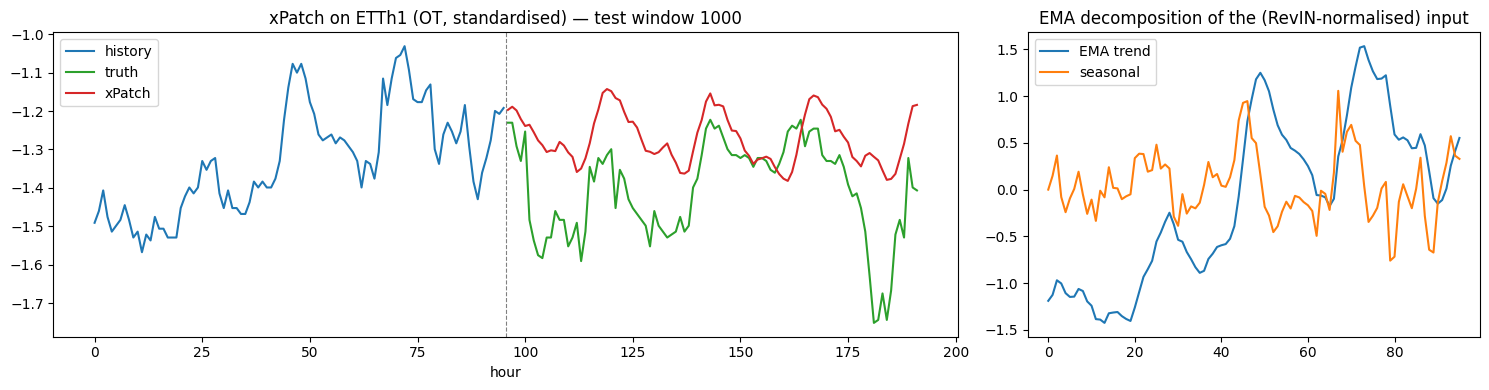

In [10]:
k = 1000
x, y = test_ds[k]
ot = cols.index("OT")
with torch.no_grad():
    seas, trend = model.decomp(model.revin_layer(x.unsqueeze(0).to(device), "norm"))
fig, ax = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(np.arange(L), x[:, ot].numpy(), label="history", color="tab:blue")
ax[0].plot(np.arange(L, L + H), y[:, ot].numpy(), label="truth", color="tab:green")
ax[0].plot(np.arange(L, L + H), pred[k, :, ot], label="xPatch", color="tab:red")
ax[0].axvline(L - 0.5, color="gray", ls="--", lw=0.8)
ax[0].set_title(f"xPatch on ETTh1 (OT, standardised) — test window {k}"); ax[0].set_xlabel("hour"); ax[0].legend()
ax[1].plot(trend[0, :, ot].cpu(), label="EMA trend"); ax[1].plot(seas[0, :, ot].cpu(), label="seasonal")
ax[1].set_title("EMA decomposition of the (RevIN-normalised) input"); ax[1].legend()
plt.tight_layout(); plt.show()

## Results

In [11]:
results = {
    "model": "xPatch",
    "paper": "xPatch: Dual-Stream Time Series Forecasting with Exponential Seasonal-Trend Decomposition (arXiv:2412.17323)",
    "venue": "AAAI 2025",
    "type": "supervised",
    "lookback": L, "horizon": H,
    "mse": round(mse, 4), "mae": round(mae, 4),
    "paper_mse": PAPER_MSE, "paper_mae": PAPER_MAE,
    "params": n_params,
    "train_or_infer_seconds": round(train_seconds, 1),
    "notes": (f"From-scratch re-implementation of the official code with the unified-setting hyper-parameters (xPatch_unified.sh): "
              f"EMA alpha=0.3, patch 16/8, AdamW lr=5e-4, bs=2048, up to 100 epochs, patience 10, arctan-weighted L1 loss, sigmoid LR. "
              f"Seed {SEED}. Paper number is Table 13 (unified lookback L=96); the paper's hyper-parameter-search setting (longer lookback) reports 0.354/0.379. "
              f"Metrics over all {len(test_ds)} stride-1 test windows; with the official drop_last test loader ({n_dl} windows) "
              f"MSE={mse_dl:.4f} MAE={mae_dl:.4f}."),
}
print(json.dumps(results, indent=2))
try:
    with open("results_xpatch_dual_stream.json", "w") as f:
        json.dump(results, f, indent=2)
except Exception as e:
    print("could not write results file:", e)

{
  "model": "xPatch",
  "paper": "xPatch: Dual-Stream Time Series Forecasting with Exponential Seasonal-Trend Decomposition (arXiv:2412.17323)",
  "venue": "AAAI 2025",
  "type": "supervised",
  "lookback": 96,
  "horizon": 96,
  "mse": 0.3788,
  "mae": 0.3913,
  "paper_mse": 0.376,
  "paper_mae": 0.386,
  "params": 143982,
  "train_or_infer_seconds": 8.3,
  "notes": "From-scratch re-implementation of the official code with the unified-setting hyper-parameters (xPatch_unified.sh): EMA alpha=0.3, patch 16/8, AdamW lr=5e-4, bs=2048, up to 100 epochs, patience 10, arctan-weighted L1 loss, sigmoid LR. Seed 2024. Paper number is Table 13 (unified lookback L=96); the paper's hyper-parameter-search setting (longer lookback) reports 0.354/0.379. Metrics over all 2785 stride-1 test windows; with the official drop_last test loader (2048 windows) MSE=0.3758 MAE=0.3870."
}


## Using your own data

1. Replace `load_etth1` with a loader returning `(train, val, test)` arrays of shape `(time, channels)` (scale with training statistics only; prefix `val`/`test` with the last `L` rows of the previous split).
2. Set `Config.enc_in` to your number of channels and `pred_len` to your horizon (`pred_len` must be divisible by 4 because of the two `AvgPool(2)` layers in the trend stream).
3. xPatch is channel-independent and cheap, so longer lookbacks are affordable: the paper's search setting uses `seq_len` 336/512/720 (`scripts/xPatch_search.sh`), which usually helps on long, smooth series.
4. `alpha` controls the EMA smoothness: smaller α → smoother trend, more signal routed to the non-linear seasonal stream.